# Data Exploration - TrashNet
Notebook ini mengeksplorasi dataset TrashNet untuk melihat distribusi kelas, mengecek integritas gambar, dan memvisualisasikan data.

In [5]:
import os
import glob
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image
import random
import numpy as np

# Konfigurasi path
RAW_DATA_DIR = '../data/raw'
classes = sorted([d for d in os.listdir(RAW_DATA_DIR) if os.path.isdir(os.path.join(RAW_DATA_DIR, d))])
print(f'Kelas yang tersedia: {classes}')

Matplotlib is building the font cache; this may take a moment.


Kelas yang tersedia: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [6]:
# 1. Hitung jumlah gambar per kelas dan Deteksi file corrupt
class_counts = Counter()
corrupt_files = []
filepaths_per_class = {cls: [] for cls in classes}

print('Memeriksa integritas file...')
for cls in classes:
    cls_dir = os.path.join(RAW_DATA_DIR, cls)
    files = glob.glob(os.path.join(cls_dir, '*.*'))
    for f in files:
        try:
            with Image.open(f) as img:
                img.verify() # Cek apakah file rusak
            class_counts[cls] += 1
            filepaths_per_class[cls].append(f)
        except Exception as e:
            corrupt_files.append((f, str(e)))

print(f'Total gambar valid: {sum(class_counts.values())}')
if corrupt_files:
    print(f'Ditemukan {len(corrupt_files)} file corrupt:')
    for f, err in corrupt_files[:10]:
        print(f' - {f}: {err}')
else:
    print('Tidak ditemukan file corrupt!')

Memeriksa integritas file...
Total gambar valid: 2527
Tidak ditemukan file corrupt!


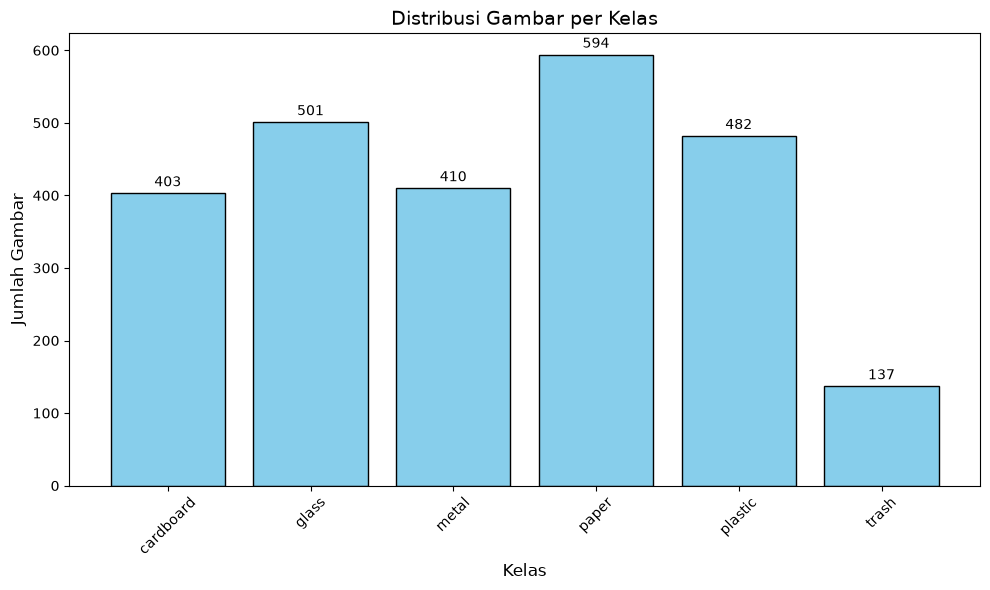

In [7]:
# 2. Bar chart untuk cek class imbalance
plt.figure(figsize=(10, 6))
bars = plt.bar(class_counts.keys(), class_counts.values(), color='skyblue', edgecolor='black')
plt.title('Distribusi Gambar per Kelas', fontsize=14)
plt.xlabel('Kelas', fontsize=12)
plt.ylabel('Jumlah Gambar', fontsize=12)
plt.xticks(rotation=45)

# Menambahkan label angka di atas bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom')

plt.tight_layout()
plt.show()

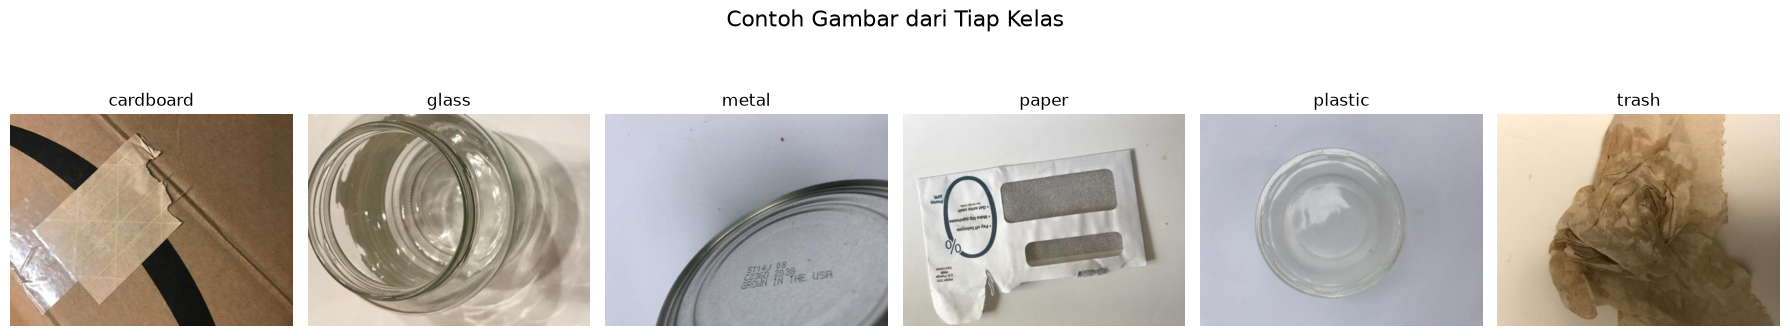

In [8]:
# 3. Visualisasikan 1 contoh gambar dari tiap kelas dalam satu grid
fig, axes = plt.subplots(1, len(classes), figsize=(18, 4))
fig.suptitle('Contoh Gambar dari Tiap Kelas', fontsize=16)

for i, cls in enumerate(classes):
    if filepaths_per_class[cls]:
        sample_path = random.choice(filepaths_per_class[cls])
        img = Image.open(sample_path)
        axes[i].imshow(img)
        axes[i].set_title(cls)
        axes[i].axis('off')

plt.tight_layout()
plt.show()

In [9]:
# 4. Cek ukuran gambar dan format (RGB/grayscale) dari sample acak
print('Sample Informasi Gambar (Ukuran & Format):')
print('-' * 50)
for cls in classes:
    if filepaths_per_class[cls]:
        sample_path = random.choice(filepaths_per_class[cls])
        with Image.open(sample_path) as img:
            print(f'Kelas: {cls.ljust(10)} | Mode (Warna): {img.mode.ljust(4)} | Dimensi (W x H): {str(img.size).ljust(12)} | Format: {img.format}')

Sample Informasi Gambar (Ukuran & Format):
--------------------------------------------------
Kelas: cardboard  | Mode (Warna): RGB  | Dimensi (W x H): (512, 384)   | Format: JPEG
Kelas: glass      | Mode (Warna): RGB  | Dimensi (W x H): (512, 384)   | Format: JPEG
Kelas: metal      | Mode (Warna): RGB  | Dimensi (W x H): (512, 384)   | Format: JPEG
Kelas: paper      | Mode (Warna): RGB  | Dimensi (W x H): (512, 384)   | Format: JPEG
Kelas: plastic    | Mode (Warna): RGB  | Dimensi (W x H): (512, 384)   | Format: JPEG
Kelas: trash      | Mode (Warna): RGB  | Dimensi (W x H): (512, 384)   | Format: JPEG
